<a href="https://colab.research.google.com/github/sileysa/PCVK26_26_SILEYSA/blob/main/Week7_26_Kelompok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Library

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Baca citra gradient.jpg

In [3]:
# ============================================
# PCVK WEEK 7
# NOMOR 1 - MEMBACA CITRA GRADIENT
# ============================================

filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'

gradient = cv.imread(filename)

if gradient is None:
    print("Citra gradient tidak ditemukan!")
else:
    print("Citra gradient berhasil dibaca")
    print("Ukuran citra :", gradient.shape)

Citra gradient berhasil dibaca
Ukuran citra : (540, 960, 3)


# Tampilkan citra gradient

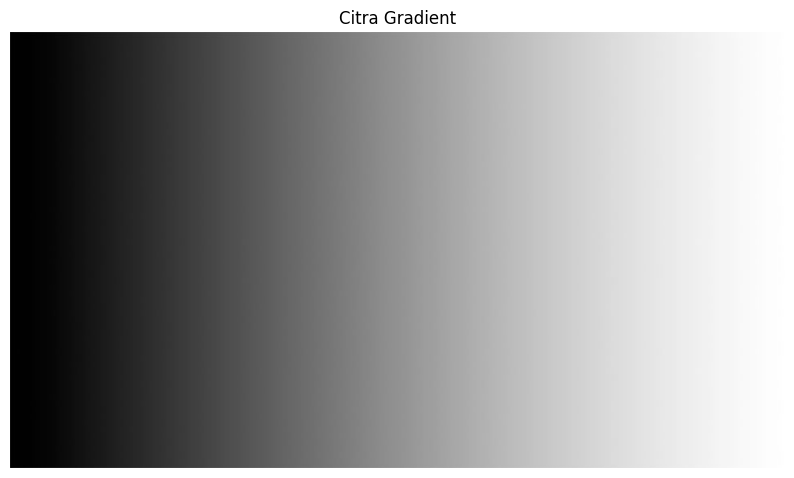

In [4]:
plt.figure(figsize=(10, 6))

plt.imshow(
    cv.cvtColor(gradient, cv.COLOR_BGR2RGB)
)

plt.title('Citra Gradient')
plt.axis('off')

plt.show()

# Ubah Gradient ke Grayscale

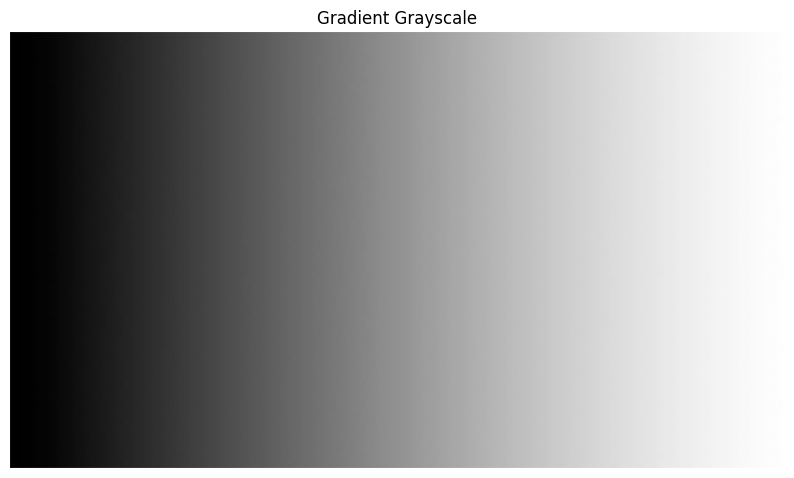

In [5]:
# ============================================
# GLOBAL THRESHOLDING
# GRAYSCALE
# ============================================

gray_gradient = cv.cvtColor(
    gradient,
    cv.COLOR_BGR2GRAY
)

plt.figure(figsize=(10, 6))

plt.imshow(
    gray_gradient,
    cmap='gray'
)

plt.title('Gradient Grayscale')
plt.axis('off')

plt.show()

# Global Thresholding

In [6]:
# ============================================
# GLOBAL THRESHOLDING
# THRESHOLD = 200
# ============================================

threshold_value = 200

_, binary = cv.threshold(
    gray_gradient,
    threshold_value,
    255,
    cv.THRESH_BINARY
)

_, binary_inv = cv.threshold(
    gray_gradient,
    threshold_value,
    255,
    cv.THRESH_BINARY_INV
)

_, trunc = cv.threshold(
    gray_gradient,
    threshold_value,
    255,
    cv.THRESH_TRUNC
)

_, tozero = cv.threshold(
    gray_gradient,
    threshold_value,
    255,
    cv.THRESH_TOZERO
)

_, tozero_inv = cv.threshold(
    gray_gradient,
    threshold_value,
    255,
    cv.THRESH_TOZERO_INV
)

# Tampilkan Semua Hasil

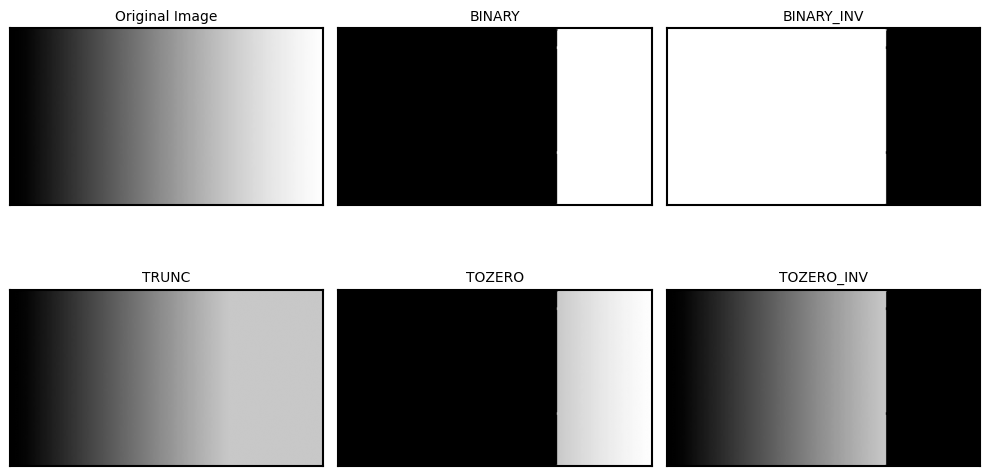

In [7]:
# ============================================
# HASIL GLOBAL THRESHOLDING
# ============================================

titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

images = [
    gradient,
    binary,
    binary_inv,
    trunc,
    tozero,
    tozero_inv
]

plt.figure(figsize=(10, 6))

for i in range(6):
    ax = plt.subplot(2, 3, i + 1)

    # Menampilkan gambar
    ax.imshow(images[i], cmap='gray', vmin=0, vmax=255)

    # Judul
    ax.set_title(titles[i], fontsize=10)

    # Hilangkan angka sumbu
    ax.set_xticks([])
    ax.set_yticks([])

    # ========================================
    # GARIS TEPI HITAM
    # ========================================
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

# Baca sudoku-original.jpg

In [8]:
# ============================================
# NOMOR 4
# ADAPTIVE THRESHOLDING MANUAL
# ============================================

filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'

img_sudoku = cv.imread(filename)

if img_sudoku is None:
    print("Gambar sudoku tidak ditemukan!")
else:
    print("Gambar sudoku berhasil dibaca")
    print("Ukuran :", img_sudoku.shape)

Gambar sudoku berhasil dibaca
Ukuran : (423, 419, 3)


# Global Threshold Manual — T = 127

In [10]:
# ============================================
# GLOBAL THRESHOLD MANUAL
# T = 127
# ============================================

# Konversi ke Grayscale terlebih dahulu
gray_sudoku = cv.cvtColor(img_sudoku, cv.COLOR_BGR2GRAY)

T = 127

global_manual = np.zeros_like(gray_sudoku)

global_manual[
    gray_sudoku > T
] = 255

# Adaptive Mean Manual

In [11]:
# ============================================
# ADAPTIVE MEAN - MANUAL
# Window 11x11
# C = 2
# ============================================

def adaptive_mean_manual(
    image,
    block_size=11,
    C=2
):

    pad = block_size // 2

    padded = np.pad(
        image,
        pad,
        mode='reflect'
    )

    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            # Ambil window 11x11
            window = padded[
                i:i + block_size,
                j:j + block_size
            ]

            # Hitung rata-rata lokal
            local_mean = np.mean(window)

            # Threshold lokal
            threshold = local_mean - C

            # Binarisasi
            if image[i, j] > threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0

    return result

# Adaptive Gaussian Manual

In [12]:
# ============================================
# MEMBUAT GAUSSIAN KERNEL MANUAL
# ============================================

def gaussian_kernel(
    size=11,
    sigma=2
):

    center = size // 2

    x = np.arange(
        -center,
        center + 1
    )

    y = np.arange(
        -center,
        center + 1
    )

    X, Y = np.meshgrid(x, y)

    kernel = np.exp(
        -(X**2 + Y**2) /
        (2 * sigma**2)
    )

    # Normalisasi
    kernel = kernel / np.sum(kernel)

    return kernel

In [13]:
kernel = gaussian_kernel(
    size=11,
    sigma=2
)

print(kernel)
print("\nJumlah seluruh kernel =", kernel.sum())

[[7.76553851e-05 2.39195426e-04 5.73799997e-04 1.07199952e-03
  1.55975010e-03 1.76742842e-03 1.55975010e-03 1.07199952e-03
  5.73799997e-04 2.39195426e-04 7.76553851e-05]
 [2.39195426e-04 7.36773780e-04 1.76742842e-03 3.30199100e-03
  4.80436855e-03 5.44406279e-03 4.80436855e-03 3.30199100e-03
  1.76742842e-03 7.36773780e-04 2.39195426e-04]
 [5.73799997e-04 1.76742842e-03 4.23984037e-03 7.92106463e-03
  1.15250810e-02 1.30596277e-02 1.15250810e-02 7.92106463e-03
  4.23984037e-03 1.76742842e-03 5.73799997e-04]
 [1.07199952e-03 3.30199100e-03 7.92106463e-03 1.47984970e-02
  2.15316860e-02 2.43985967e-02 2.15316860e-02 1.47984970e-02
  7.92106463e-03 3.30199100e-03 1.07199952e-03]
 [1.55975010e-03 4.80436855e-03 1.15250810e-02 2.15316860e-02
  3.13284183e-02 3.54997488e-02 3.13284183e-02 2.15316860e-02
  1.15250810e-02 4.80436855e-03 1.55975010e-03]
 [1.76742842e-03 5.44406279e-03 1.30596277e-02 2.43985967e-02
  3.54997488e-02 4.02264854e-02 3.54997488e-02 2.43985967e-02
  1.30596277e-02

# Adaptive Gaussian Manual

In [14]:
# ============================================
# ADAPTIVE GAUSSIAN - MANUAL
# Window 11x11
# C = 2
# Sigma = 2
# ============================================

def adaptive_gaussian_manual(
    image,
    block_size=11,
    sigma=2,
    C=2
):

    pad = block_size // 2

    kernel = gaussian_kernel(
        size=block_size,
        sigma=sigma
    )

    padded = np.pad(
        image,
        pad,
        mode='reflect'
    )

    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            # Ambil window
            window = padded[
                i:i + block_size,
                j:j + block_size
            ]

            # Weighted mean menggunakan
            # Gaussian kernel manual
            local_mean = np.sum(
                window * kernel
            )

            # Threshold lokal
            threshold = local_mean - C

            # Binarisasi
            if image[i, j] > threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0

    return result

# Jalankan Adaptive Mean & Gaussian

In [15]:
# ============================================
# MENJALANKAN ADAPTIVE THRESHOLD
# ============================================

adaptive_mean = adaptive_mean_manual(
    gray_sudoku,
    block_size=11,
    C=2
)

adaptive_gaussian = adaptive_gaussian_manual(
    gray_sudoku,
    block_size=11,
    sigma=2,
    C=2
)

# Tampilkan semua hasil

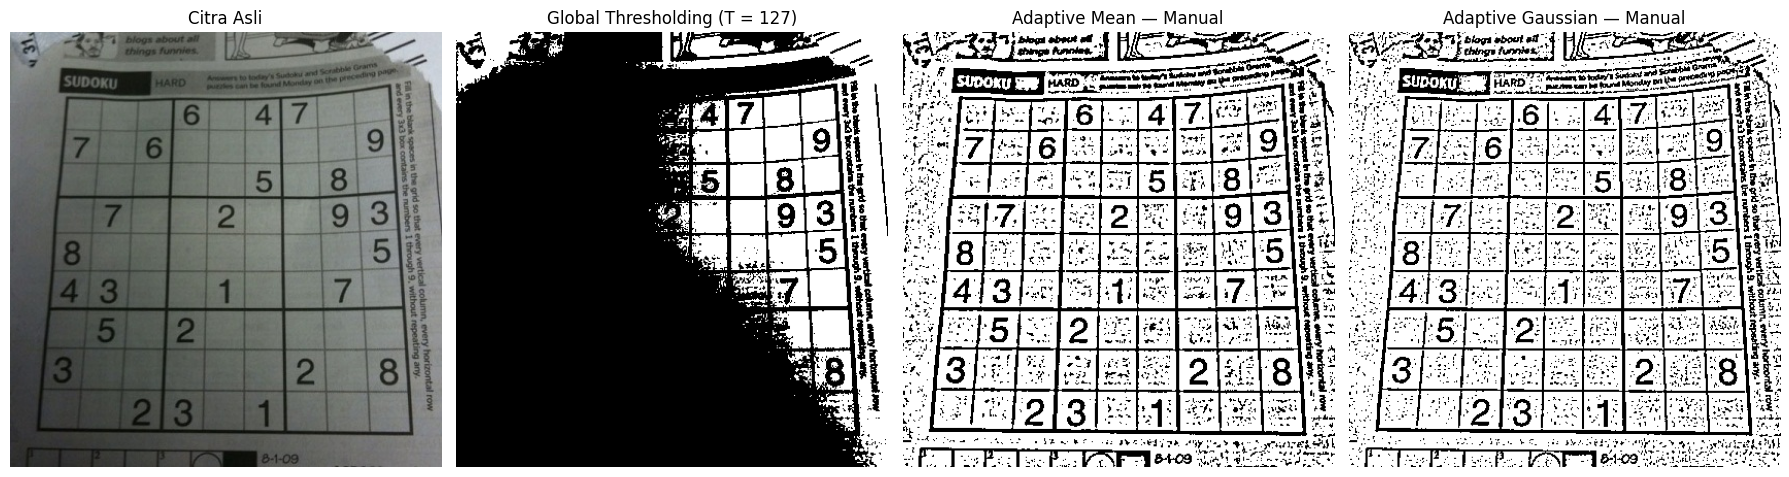

In [16]:
# ============================================
# HASIL AKHIR NOMOR 4
# ============================================

plt.figure(figsize=(18, 5))

# --------------------------------------------
# 1. CITRA ASLI
# --------------------------------------------
plt.subplot(1, 4, 1)

plt.imshow(
    cv.cvtColor(
        img_sudoku,
        cv.COLOR_BGR2RGB
    )
)

plt.title('Citra Asli')
plt.axis('off')


# --------------------------------------------
# 2. GLOBAL THRESHOLD
# --------------------------------------------
plt.subplot(1, 4, 2)

plt.imshow(
    global_manual,
    cmap='gray'
)

plt.title('Global Thresholding (T = 127)')
plt.axis('off')


# --------------------------------------------
# 3. ADAPTIVE MEAN
# --------------------------------------------
plt.subplot(1, 4, 3)

plt.imshow(
    adaptive_mean,
    cmap='gray'
)

plt.title('Adaptive Mean — Manual')
plt.axis('off')


# --------------------------------------------
# 4. ADAPTIVE GAUSSIAN
# --------------------------------------------
plt.subplot(1, 4, 4)

plt.imshow(
    adaptive_gaussian,
    cmap='gray'
)

plt.title('Adaptive Gaussian — Manual')
plt.axis('off')


plt.tight_layout()
plt.show()

# Baca lena_gs_lc2.jpg

In [17]:
# ============================================
# NOMOR 5A - OTSU THRESHOLDING
# CITRA LENA
# ============================================

filename = '/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg'

img = cv.imread(filename, 0)

print("Ukuran citra :", img.shape)

Ukuran citra : (512, 512)


# Gaussian Blur dan Global Threshold

In [18]:
# ============================================
# GAUSSIAN BLUR
# ============================================

blur = cv.GaussianBlur(
    img,
    (5, 5),
    0
)

thresh = 127

# Fungsi Otsu Manual

In [19]:
# ============================================
# OTSU MANUAL
# TANPA LIBRARY OTSU
# ============================================

def otsu(gray):

    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number

    his, bins = np.histogram(
        gray,
        np.arange(0, 257)
    )

    final_thresh = -1
    final_value = -1

    intensity_arr = np.arange(256)

    for t in bins[1:-1]:

        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        if pcb == 0 or pcf == 0:
            continue

        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)

        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)

        value = (
            Wb * Wf *
            (mub - muf) ** 2
        )

        if value > final_value:

            final_thresh = t
            final_value = value

    final_img = gray.copy()

    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0

    return final_img, final_thresh

# Jalankan Otsu Manual

In [20]:
# ============================================
# MENJALANKAN OTSU MANUAL
# ============================================

otsu_biner, otsu_thresh = otsu(blur)

print("Threshold Otsu =", otsu_thresh)

Threshold Otsu = 93


# Global Threshold dengan T = 127

In [21]:
# ============================================
# GLOBAL THRESHOLDING
# T = 127
# ============================================

ret, th1 = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)

print("Global Threshold =", thresh)

Global Threshold = 127


# Tampilkan hasil

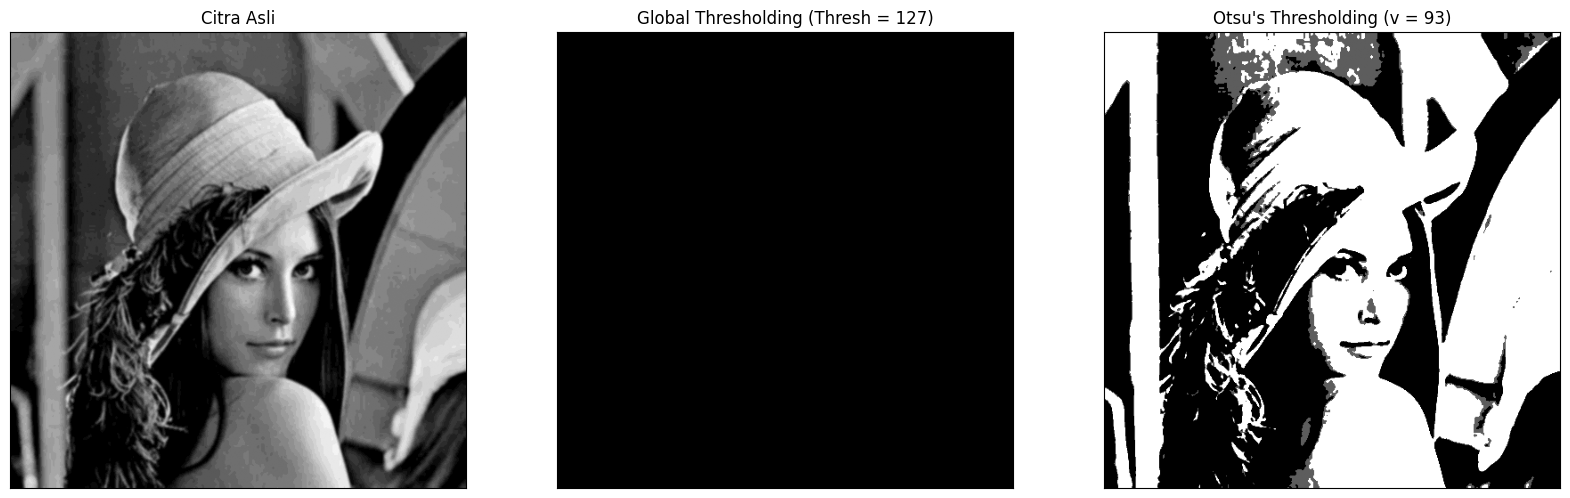

In [22]:
# ============================================
# PERBANDINGAN
# ============================================

x = (
    "Otsu's Thresholding (v = "
    + str(otsu_thresh)
    + ")"
)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    x
]

citra3 = [
    blur,
    th1,
    otsu_biner
]

plt.figure(figsize=(20, 15))

for i in range(len(citra3)):

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        citra3[i],
        'gray'
    )

    plt.title(
        titles[i]
    )

    plt.xticks([])
    plt.yticks([])

plt.show()

# Buat Histogram Lena

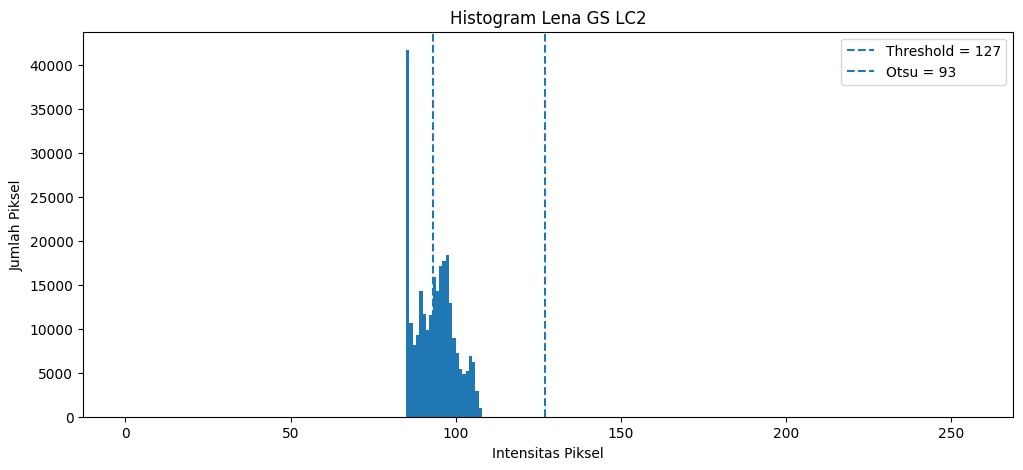

In [23]:
# ============================================
# HISTOGRAM CITRA LENA
# ============================================

plt.figure(figsize=(12, 5))

plt.hist(
    blur.ravel(),
    bins=256,
    range=[0, 256]
)

plt.axvline(
    thresh,
    linestyle='--',
    label='Threshold = 127'
)

plt.axvline(
    otsu_thresh,
    linestyle='--',
    label=f'Otsu = {otsu_thresh}'
)

plt.xlabel('Intensitas Piksel')
plt.ylabel('Jumlah Piksel')
plt.title('Histogram Lena GS LC2')

plt.legend()

plt.show()

# Cek nilai minimum dan maksimum

In [24]:
# ============================================
# CEK RENTANG INTENSITAS
# ============================================

print("Nilai minimum :", np.min(blur))
print("Nilai maksimum :", np.max(blur))
print("Threshold      :", thresh)
print("Threshold Otsu :", otsu_thresh)

Nilai minimum : 85
Nilai maksimum : 108
Threshold      : 127
Threshold Otsu : 93


1. Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

Hasil Binary Thresholding dengan Thresh = 127 menghasilkan citra hitam seluruhnya karena nilai intensitas piksel pada citra lena_gs_lc2.jpg setelah Gaussian Blur hanya berada pada rentang 85–108. Sementara itu, pada Binary Thresholding, piksel yang memiliki nilai lebih besar dari 127 akan diubah menjadi 255 (putih), sedangkan piksel yang kurang dari atau sama dengan 127 menjadi 0 (hitam). Karena nilai maksimum citra hanya 108, tidak ada piksel yang lebih besar dari 127 sehingga seluruh piksel berubah menjadi 0 dan gambar menjadi hitam.

Berdasarkan perhitungan Otsu manual, diperoleh nilai threshold sebesar 93. Nilai tersebut berada di dalam rentang intensitas citra 85–108 sehingga terdapat piksel yang lebih besar dari 93 dan hasil threshold masih menampilkan objek Lena. Dengan demikian, pada percobaan ini threshold 93 dapat digunakan agar gambar Lena masih terlihat.

# KTP Fulan

In [25]:
# ============================================
# 5B - OTSU PADA KTP FULAN
# ============================================

filename_ktp = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'

img_ktp = cv.imread(
    filename_ktp,
    0
)

print("Ukuran KTP :", img_ktp.shape)

Ukuran KTP : (458, 694)


# Grayscale KTP + Blur

In [26]:
# ============================================
# BLUR KTP
# ============================================

blur_ktp = cv.GaussianBlur(
    img_ktp,
    (5, 5),
    0
)

# Global Threshold KTP

In [27]:
# ============================================
# GLOBAL THRESHOLD KTP
# ============================================

ret_ktp, global_ktp = cv.threshold(
    blur_ktp,
    127,
    255,
    cv.THRESH_BINARY
)

# Otsu Manual KTP

In [28]:
# ============================================
# OTSU MANUAL KTP
# ============================================

otsu_ktp, otsu_thresh_ktp = otsu(
    blur_ktp
)

print(
    "Threshold Otsu KTP =",
    otsu_thresh_ktp
)

Threshold Otsu KTP = 166


# Tampilkan perbandingan KTP

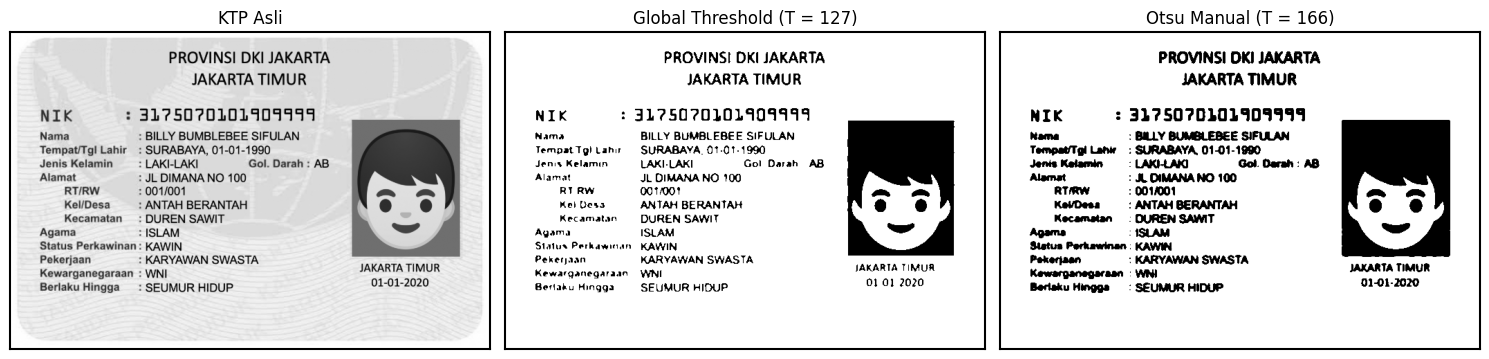

In [29]:
# ============================================
# PERBANDINGAN KTP
# ============================================

titles = [
    'KTP Asli',
    'Global Threshold (T = 127)',
    f"Otsu Manual (T = {otsu_thresh_ktp})"
]

images = [
    img_ktp,
    global_ktp,
    otsu_ktp
]

plt.figure(figsize=(15, 5))

for i in range(3):

    ax = plt.subplot(1, 3, i + 1)

    ax.imshow(
        images[i],
        cmap='gray',
        vmin=0,
        vmax=255
    )

    ax.set_title(titles[i])

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

Pada citra KTP Fulan, diperoleh nilai threshold Otsu sebesar 166, sedangkan global threshold yang digunakan adalah 127. Hasil keduanya dapat berbeda karena Otsu menentukan nilai ambang berdasarkan distribusi intensitas piksel pada citra, sedangkan global threshold menggunakan nilai ambang yang ditentukan secara manual. Dengan demikian, Otsu dapat menghasilkan nilai threshold yang berbeda untuk setiap citra sesuai karakteristik histogramnya.

Berdasarkan percobaan, Otsu Thresholding mampu menentukan nilai ambang secara otomatis berdasarkan distribusi intensitas citra. Pada lena_gs_lc2.jpg diperoleh threshold 93, sedangkan pada ktp_fulan.jpg diperoleh threshold 166. Perbedaan tersebut menunjukkan bahwa setiap citra memiliki distribusi intensitas yang berbeda sehingga nilai threshold yang optimal juga dapat berbeda.

# Load citra + tentukan seed

In [30]:
# ============================================
# TUGAS 6A - REGION GROWING MANUAL
# ============================================

image = data.coins()

# Gaussian smoothing
# Hasil ini yang digunakan untuk region growing
image_float = gaussian(image, sigma=2) * 255

# Tampilkan citra + seed

In [31]:
# ============================================
# MENAMPILKAN CITRA DAN SEED
# ============================================

seed = (36, 43)

# Intensitas pada titik seed
seed_intensity = image_float[seed]

print("Seed (baris, kolom):", seed)
print("Intensitas seed:", seed_intensity)

Seed (baris, kolom): (36, 43)
Intensitas seed: 144.70655571875804


# Fungsi Region Growing Manual

In [32]:
# ============================================
# REGION GROWING MANUAL
# ============================================

def region_growing(image, seed, threshold):

    rows, cols = image.shape

    # Menyimpan piksel yang sudah masuk region
    visited = np.zeros((rows, cols), dtype=bool)

    # Hasil region
    region = np.zeros((rows, cols), dtype=np.uint8)

    # Queue untuk proses pertumbuhan region
    queue = deque()

    # Masukkan seed
    queue.append(seed)
    visited[seed] = True
    region[seed] = 255

    # Nilai awal region
    region_sum = float(image[seed])
    region_count = 1

    # 8-connectivity
    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    while queue:

        r, c = queue.popleft()

        # Rata-rata intensitas region saat ini
        region_mean = region_sum / region_count

        # Periksa 8 tetangga
        for dr, dc in neighbors:

            nr = r + dr
            nc = c + dc

            # Pastikan koordinat masih di dalam citra
            if 0 <= nr < rows and 0 <= nc < cols:

                # Belum pernah diperiksa
                if not visited[nr, nc]:

                    # Perbedaan intensitas dengan rata-rata region
                    difference = abs(
                        float(image[nr, nc]) - region_mean
                    )

                    # Jika memenuhi threshold,
                    # masukkan ke region
                    if difference <= threshold:

                        visited[nr, nc] = True
                        region[nr, nc] = 255

                        queue.append((nr, nc))

                        # Update statistik region
                        region_sum += float(image[nr, nc])
                        region_count += 1

    return region

# Jalankan T = 5, 20, 60

In [33]:
# ============================================
# REGION GROWING T = 5, 20, 60
# ============================================

thresholds = [5, 20, 60]
results = []

for T in thresholds:

    result = region_growing(
        image_float,
        seed,
        T
    )

    results.append(result)

    print(f"T = {T} --> {np.sum(result > 0)} piksel")

T = 5 --> 27 piksel
T = 20 --> 1284 piksel
T = 60 --> 95968 piksel


# Buat tampilan merah seperti modul

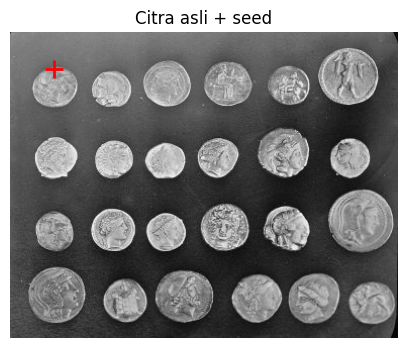

In [34]:
# ============================================
# OVERLAY REGION
# ============================================

image_seed = image.copy()

# Beri tanda merah pada seed
plt.figure(figsize=(5, 4))

plt.imshow(image_seed, cmap='gray')
plt.scatter(
    seed[1],
    seed[0],
    c='red',
    marker='+',
    s=150,
    linewidths=2
)

plt.title("Citra asli + seed")
plt.axis("off")
plt.show()

# Tampilkan hasil A

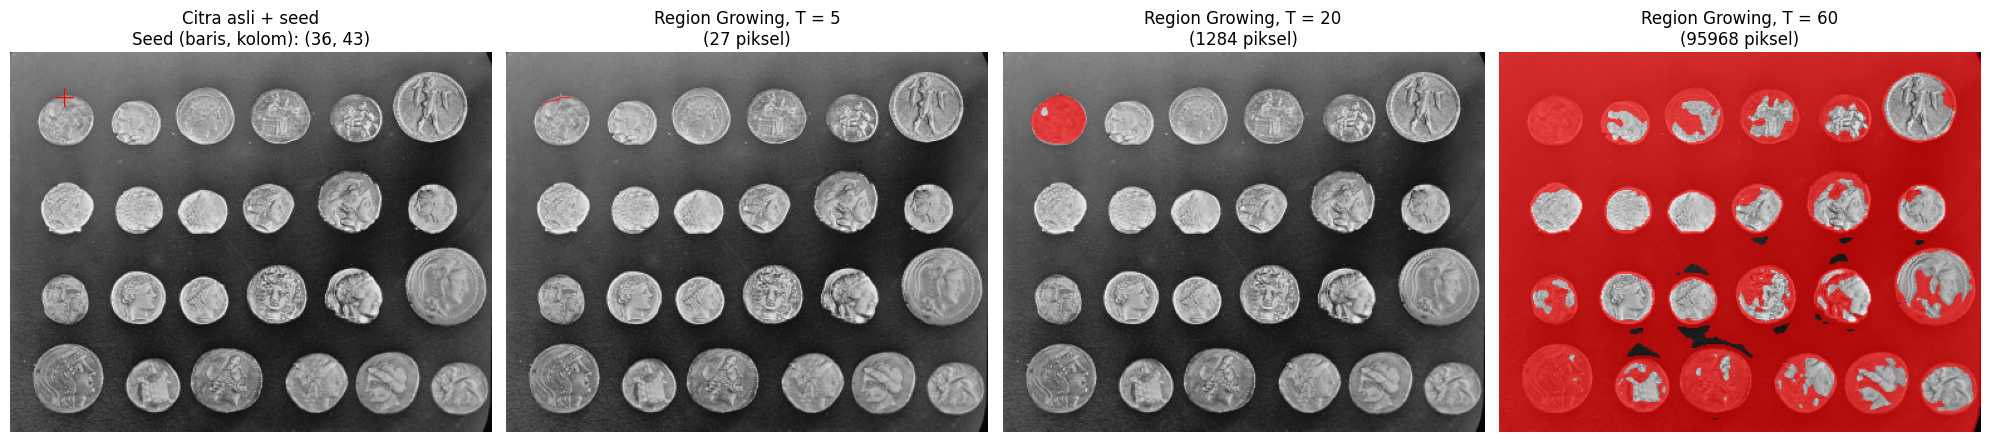

In [35]:
# ============================================
# VISUALISASI REGION GROWING
# Dibuat menyerupai output modul
# ============================================

# Ubah citra grayscale menjadi RGB
image_rgb = cv.cvtColor(image, cv.COLOR_GRAY2RGB)

# --------------------------------------------
# Citra asli + seed
# --------------------------------------------
original_with_seed = image_rgb.copy()

r, c = seed

# Tanda silang merah seperti pada modul
for i in range(-7, 8):
    if 0 <= r + i < image.shape[0]:
        original_with_seed[r + i, c] = [255, 0, 0]

for i in range(-7, 8):
    if 0 <= c + i < image.shape[1]:
        original_with_seed[r, c + i] = [255, 0, 0]


# --------------------------------------------
# Membuat overlay merah transparan
# --------------------------------------------
overlay_results = []

alpha = 0.65

for result in results:

    # Salin citra asli
    overlay = image_rgb.copy()

    # Mask hasil region growing
    mask = result > 0

    # Warna merah
    red = np.array([255, 0, 0], dtype=np.float32)

    # Piksel citra asli
    original_pixels = image_rgb[mask].astype(np.float32)

    # Campurkan citra asli + merah
    blended = (
        (1 - alpha) * original_pixels
        + alpha * red
    )

    overlay[mask] = np.clip(
        blended,
        0,
        255
    ).astype(np.uint8)

    overlay_results.append(overlay)


# ============================================
# Tampilkan 4 gambar
# ============================================

plt.figure(figsize=(20, 5))

# --------------------------------------------
# 1. Citra asli + seed
# --------------------------------------------

plt.subplot(1, 4, 1)

plt.imshow(original_with_seed)

plt.title(
    f"Citra asli + seed\n"
    f"Seed (baris, kolom): {seed}"
)

plt.axis("off")


# --------------------------------------------
# 2. T = 5
# --------------------------------------------

plt.subplot(1, 4, 2)

plt.imshow(overlay_results[0])

plt.title(
    f"Region Growing, T = 5\n"
    f"({np.sum(results[0] > 0)} piksel)"
)

plt.axis("off")


# --------------------------------------------
# 3. T = 20
# --------------------------------------------

plt.subplot(1, 4, 3)

plt.imshow(overlay_results[1])

plt.title(
    f"Region Growing, T = 20\n"
    f"({np.sum(results[1] > 0)} piksel)"
)

plt.axis("off")


# --------------------------------------------
# 4. T = 60
# --------------------------------------------

plt.subplot(1, 4, 4)

plt.imshow(overlay_results[2])

plt.title(
    f"Region Growing, T = 60\n"
    f"({np.sum(results[2] > 0)} piksel)"
)

plt.axis("off")


plt.tight_layout()
plt.show()

# 6B

In [36]:
# ============================================
# TUGAS 6B
# ============================================

image = data.coins()

# Menentukan seed

In [37]:
seed = (36, 43)

print("Seed (baris, kolom):", seed)
print("Intensitas seed:", image[seed])

Seed (baris, kolom): (36, 43)
Intensitas seed: 159


# Flood Fill

In [38]:
thresholds = [5, 20, 60]

flood_results = []

for T in thresholds:

    region = flood(
        image,
        seed,
        tolerance=T,
        connectivity=1
    )

    flood_results.append(region)

    print(
        f"Region Growing, T = {T}: "
        f"{np.sum(region)} piksel"
    )

Region Growing, T = 5: 21 piksel
Region Growing, T = 20: 919 piksel
Region Growing, T = 60: 15253 piksel


# Citra asli + seed

In [39]:
image_rgb = cv.cvtColor(
    image,
    cv.COLOR_GRAY2RGB
)

original_with_seed = image_rgb.copy()

r, c = seed

# Tanda silang merah
for i in range(-7, 8):

    if 0 <= r + i < image.shape[0]:
        original_with_seed[r + i, c] = [255, 0, 0]

for i in range(-7, 8):

    if 0 <= c + i < image.shape[1]:
        original_with_seed[r, c + i] = [255, 0, 0]

# Overlay hasil Flood Fill

In [40]:
overlay_results = []

alpha = 0.65

for region in flood_results:

    overlay = image_rgb.copy()

    mask = region

    red = np.array(
        [255, 0, 0],
        dtype=np.float32
    )

    original_pixels = (
        image_rgb[mask]
        .astype(np.float32)
    )

    blended = (
        (1 - alpha) * original_pixels
        + alpha * red
    )

    overlay[mask] = np.clip(
        blended,
        0,
        255
    ).astype(np.uint8)

    overlay_results.append(overlay)

# Menampilkan hasil

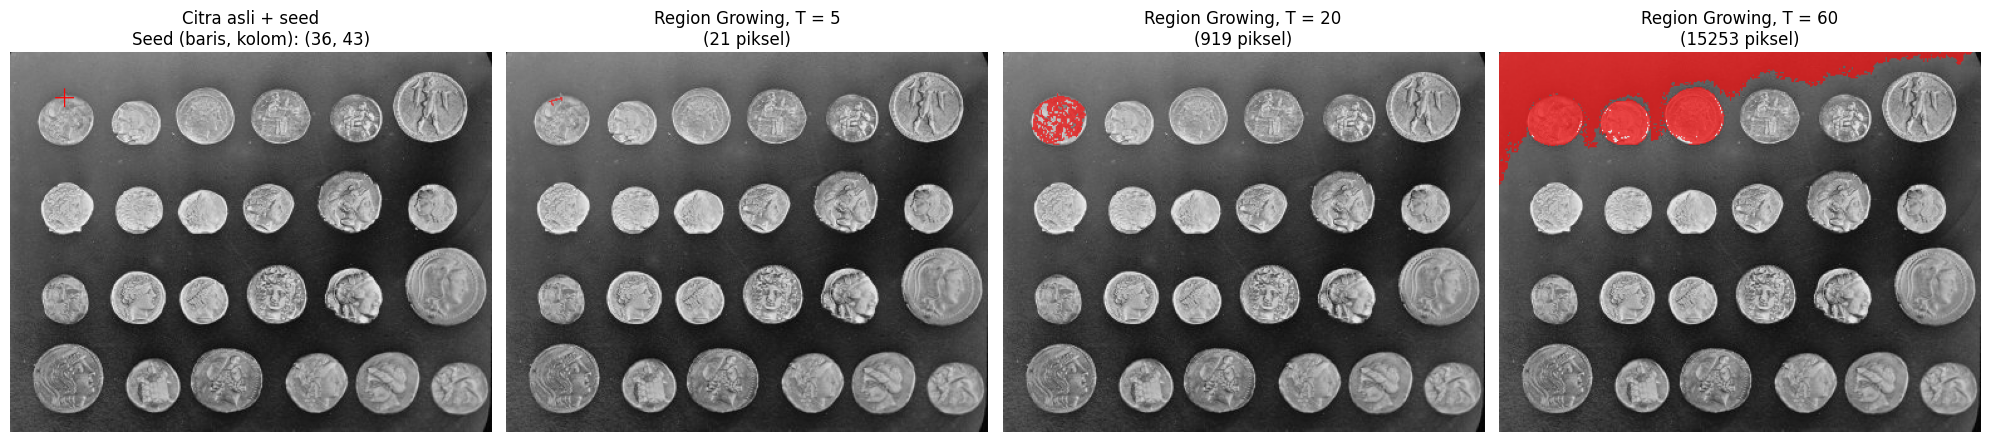

In [41]:
plt.figure(figsize=(20, 5))


# Citra asli + seed
plt.subplot(1, 4, 1)

plt.imshow(original_with_seed)

plt.title(
    f"Citra asli + seed\n"
    f"Seed (baris, kolom): {seed}"
)

plt.axis("off")


# T = 5
plt.subplot(1, 4, 2)

plt.imshow(overlay_results[0])

plt.title(
    f"Region Growing, T = 5\n"
    f"({np.sum(flood_results[0])} piksel)"
)

plt.axis("off")


# T = 20
plt.subplot(1, 4, 3)

plt.imshow(overlay_results[1])

plt.title(
    f"Region Growing, T = 20\n"
    f"({np.sum(flood_results[1])} piksel)"
)

plt.axis("off")


# T = 60
plt.subplot(1, 4, 4)

plt.imshow(overlay_results[2])

plt.title(
    f"Region Growing, T = 60\n"
    f"({np.sum(flood_results[2])} piksel)"
)

plt.axis("off")


plt.tight_layout()
plt.show()

# Baca gambar KTP

In [42]:
# ============================================
# TUGAS 7 - SEGMENTASI WARNA
# ============================================

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'

img = cv.imread(filename)

print("Gambar berhasil dibaca:", img is not None)

# OpenCV membaca gambar dalam BGR
# Ubah ke RGB untuk ditampilkan
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

print("Ukuran gambar:", img.shape)

Gambar berhasil dibaca: True
Ukuran gambar: (458, 694, 3)


# K-Means

In [43]:
# ============================================
# K-MEANS SEGMENTATION
# ============================================

# Ubah gambar menjadi data piksel
pixel_data = img_rgb.reshape(
    (-1, 3)
).astype(np.float32)

# Jumlah cluster
K = 8

# Kriteria penghentian
criteria = (
    cv.TERM_CRITERIA_EPS +
    cv.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# K-Means
compactness, labels, centers = cv.kmeans(
    pixel_data,
    K,
    None,
    criteria,
    10,
    cv.KMEANS_PP_CENTERS
)

# Ubah center menjadi uint8
centers = np.uint8(centers)

# Bentuk kembali menjadi gambar
segmented = centers[
    labels.flatten()
]

segmented = segmented.reshape(
    img_rgb.shape
)

print("K-Means selesai.")
print("Jumlah cluster:", K)
print("Ukuran hasil:", segmented.shape)

K-Means selesai.
Jumlah cluster: 8
Ukuran hasil: (458, 694, 3)


# Tampilkan Citra Asli dan K-Means

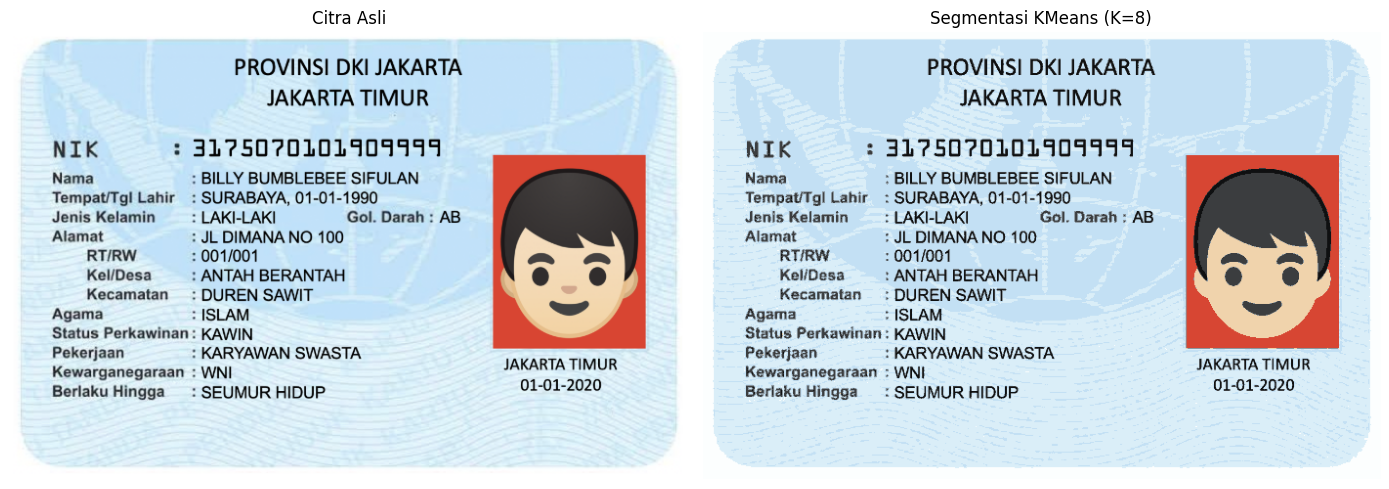

In [44]:
# ============================================
# HASIL K-MEANS
# ============================================

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented)
plt.title('Segmentasi KMeans (K=8)')
plt.axis('off')

plt.tight_layout()
plt.show()

# Konversi ke HSV

In [45]:
# ============================================
# KONVERSI RGB -> HSV
# ============================================

# OpenCV menggunakan rentang Hue 0-179
hsv = cv.cvtColor(
    segmented,
    cv.COLOR_RGB2HSV
)

H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

print("Rentang H:", H.min(), "-", H.max())
print("Rentang S:", S.min(), "-", S.max())
print("Rentang V:", V.min(), "-", V.max())

Rentang H: 3 - 105
Rentang S: 2 - 195
Rentang V: 17 - 254


# Cari warna biru

In [46]:
# ============================================
# MEMILIH WARNA BIRU
# ============================================

kelompok_biru = np.where(
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

print(
    "Jumlah piksel warna biru:",
    len(kelompok_biru[0])
)

Jumlah piksel warna biru: 247433


# Buat Mask Biru

In [47]:
# ============================================
# MASK WARNA BIRU
# ============================================

mask_biru = (
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

# Buat gambar hitam
hasil_biru = np.zeros_like(
    img_rgb
)

# Masukkan piksel biru
hasil_biru[mask_biru] = segmented[mask_biru]

# Tampilkan hasil akhir

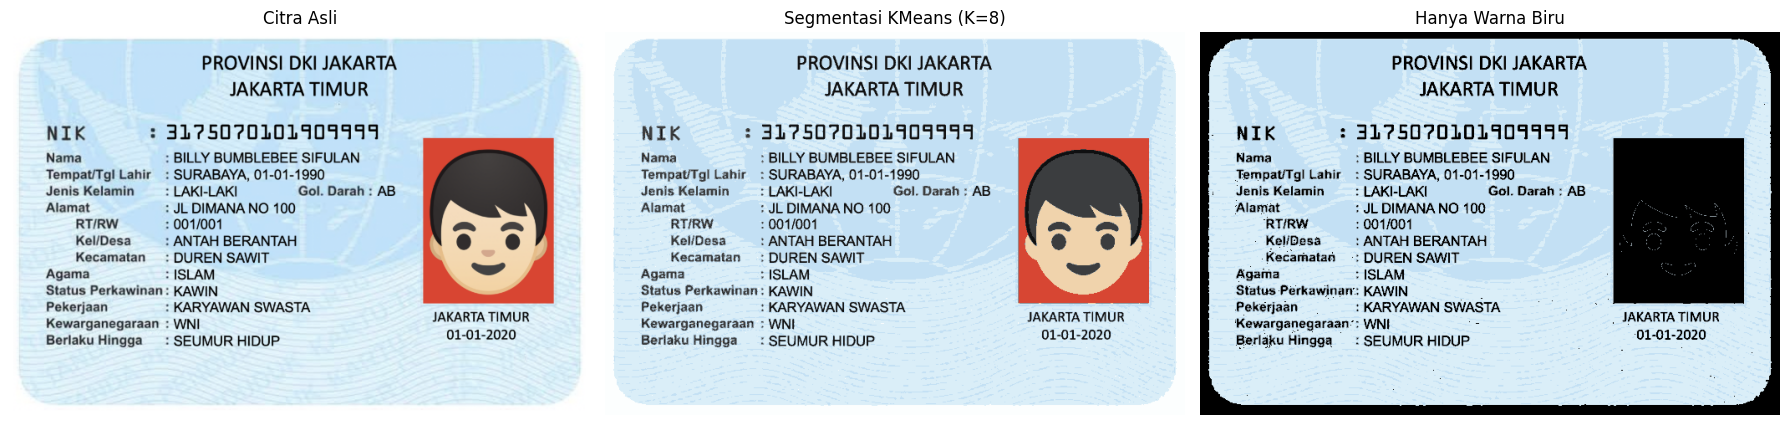

In [48]:
# ============================================
# HASIL AKHIR
# ============================================

plt.figure(figsize=(18, 5))

# Citra asli
ax1 = plt.subplot(1, 3, 1)
ax1.imshow(img_rgb)
ax1.set_title('Citra Asli')
ax1.axis('off')

# Hasil K-Means
ax2 = plt.subplot(1, 3, 2)
ax2.imshow(segmented)
ax2.set_title('Segmentasi KMeans (K=8)')
ax2.axis('off')

# Hanya warna biru
ax3 = plt.subplot(1, 3, 3)
ax3.imshow(hasil_biru)
ax3.set_title('Hanya Warna Biru')
ax3.axis('off')

# Garis tepi setiap gambar
for ax in [ax1, ax2, ax3]:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

# D2 — OCR 3 KTP

## 1. Instalasi Tesseract

In [49]:
# ============================================
# D2 - INSTALASI TESSERACT OCR
# ============================================

!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [50]:
import pytesseract

print(pytesseract.get_tesseract_version())

5.3.4


## 2. Siapkan 3 KTP

In [53]:
# ============================================
# MEMBACA 3 CITRA KTP
# ============================================

files = {
    "KTP Teman1": "/content/drive/MyDrive/PCVK/Images/KTP_Teman1.jpg",
    "KTP Teman2": "/content/drive/MyDrive/PCVK/Images/KTP_Teman2.jpg",
    "KTP Saya": "/content/drive/MyDrive/PCVK/Images/KTP1b.jpg"
}

images = {}

for name, path in files.items():

    img = cv.imread(path)

    if img is None:
        print(f"GAGAL membaca: {path}")
    else:
        images[name] = img
        print(
            f"{name}: "
            f"{img.shape[1]} x {img.shape[0]} piksel"
        )

KTP Teman1: 1569 x 978 piksel
KTP Teman2: 1433 x 934 piksel
KTP Saya: 1600 x 975 piksel


## 3. Membuat Otsu dan Adaptive untuk 3 KTP

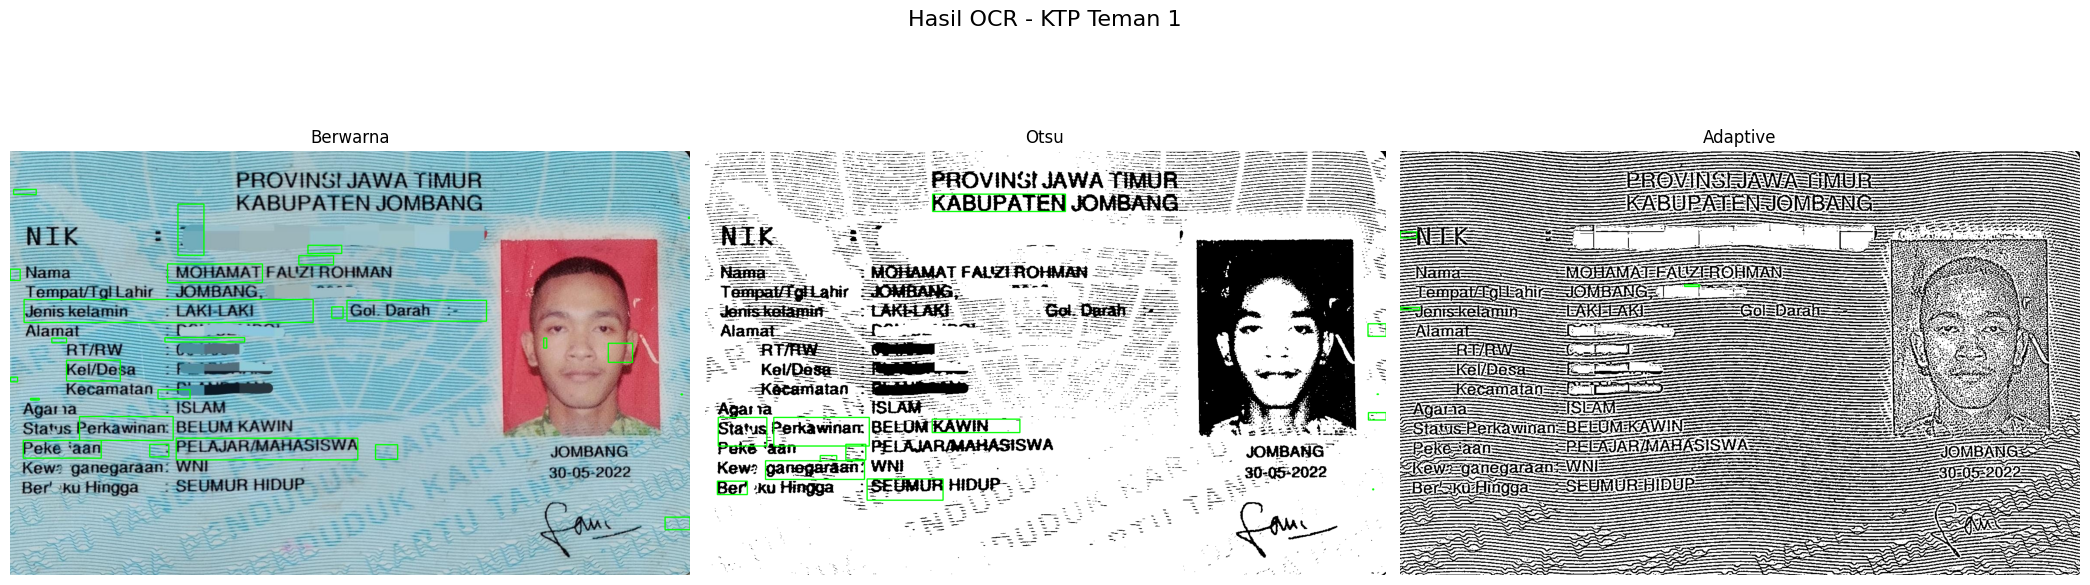

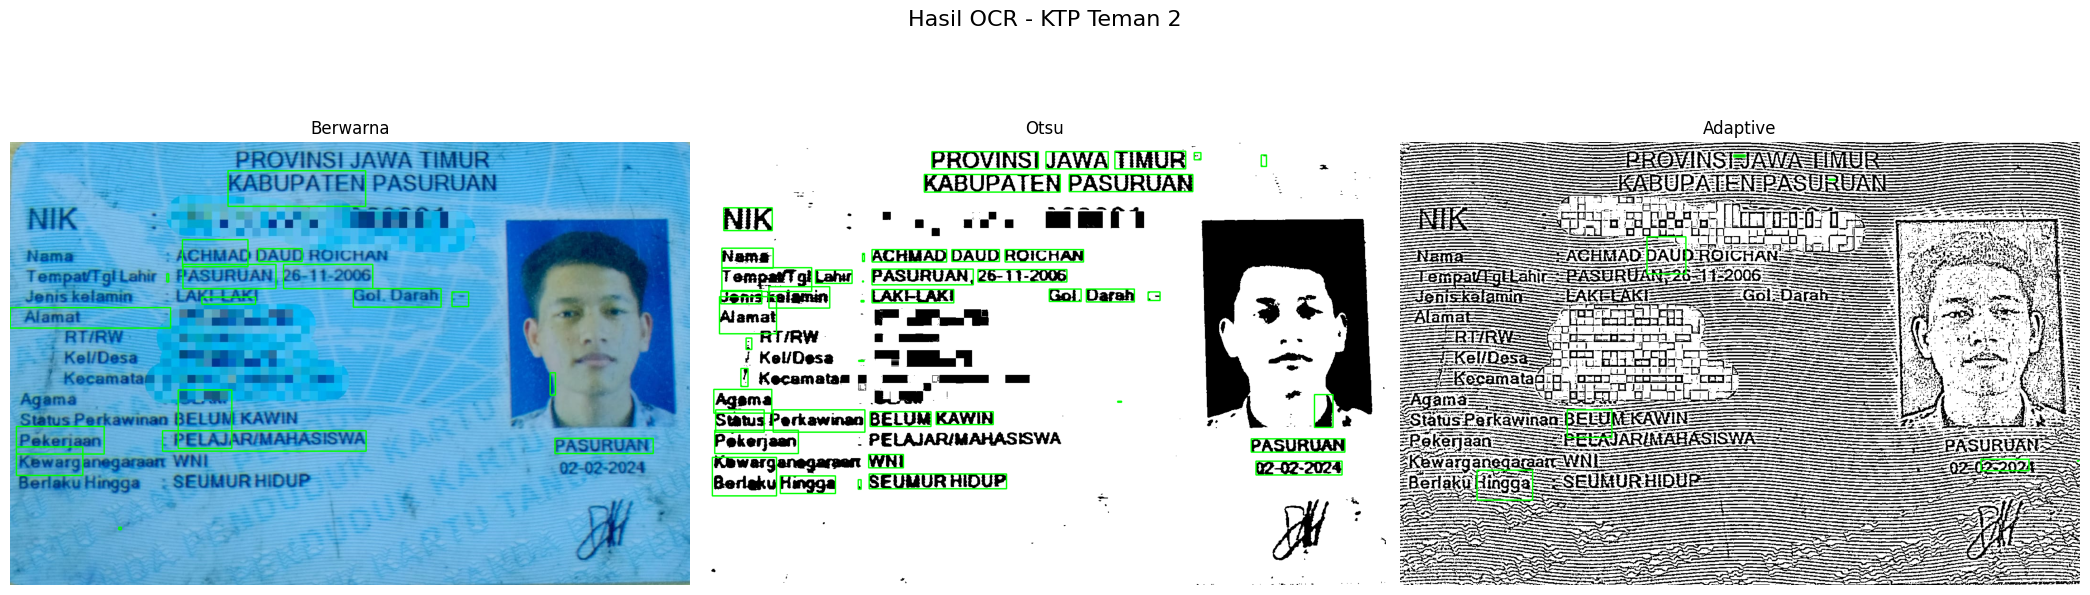

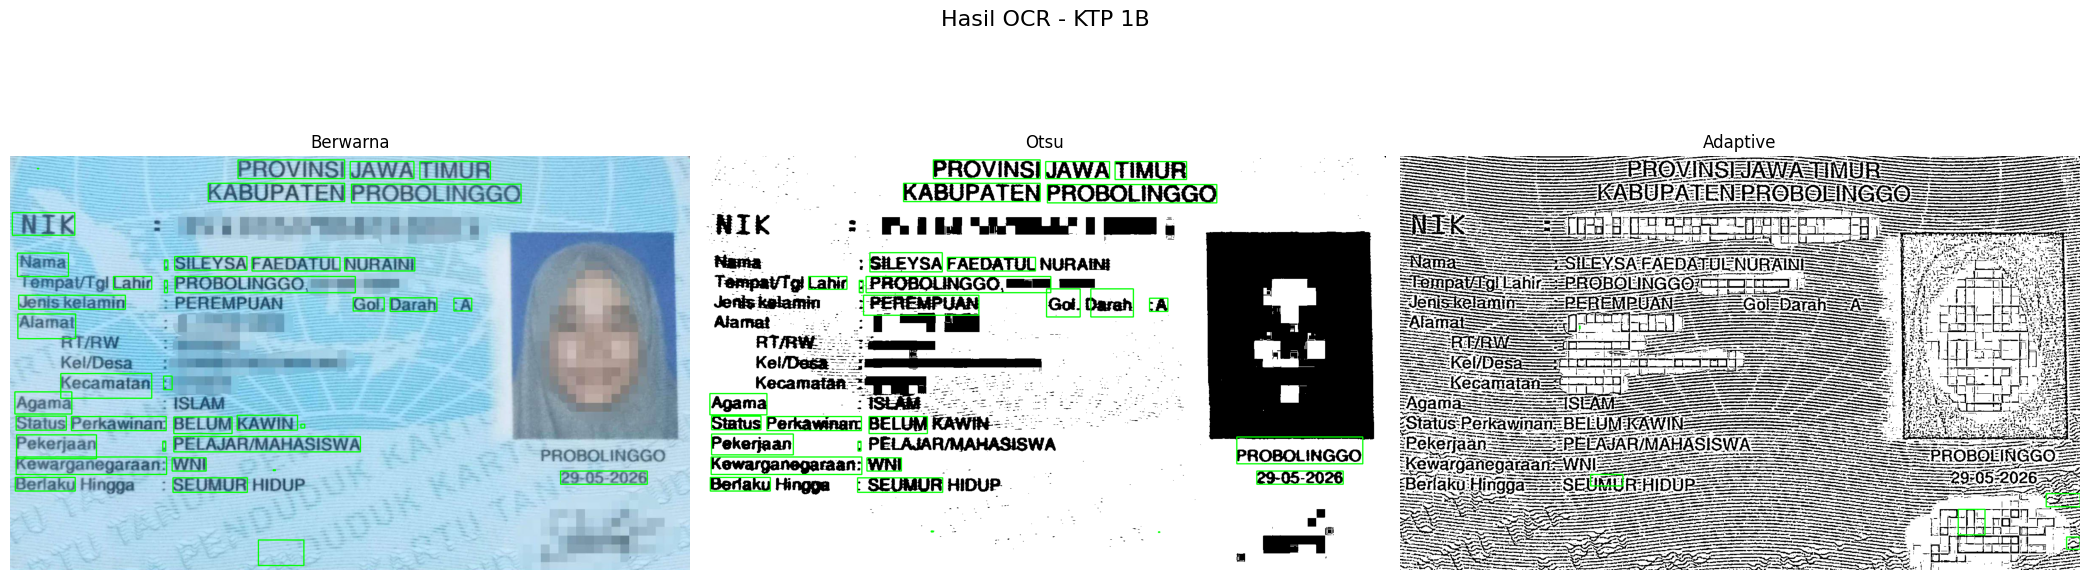


KTP Teman 1 - Berwarna
PE PROVINS JAWA TIMUR ———
— —)— TT -— SEAASASANA. tt
KABUPATEN JOMBANG”
—— ——e 55555? SE PA :
ato o- 3 5.5. —
———— Z— — —w, cs.” NS
—--— — — ———w : FA
- Nama — —. “5 MOHAMAT FALZIROHMAN ——— —— Ta
- Jeniskelamin ——- LAKELAKI ——— — — Gol-Darah — — NN &
——555—————- —E,,,,-—-—,—-—- ——-- “ang jae TT
AS ng —— aa 0
— —- mapan c— — —— t 4 2 N b. :
FS — Aa aa ta ik :
— Kel/De: ep &&&L—c io mba p :
— 558.3. - ———t,—,-—,—H.E ben Z5
— Kecamatan HS  —— Wa. 3 :
Aga MA ———— 3 “Na 5x
“Status Perkawinan: BELUM KAWIN ————— Sa Ia SAR
Peke'aan —— —: PELAJAR/MAHASISWA .. —— 5 GMBANG”—
Kew-ganagaaan: WNE-————— 5 3  —gnapnog9g AX
SA r —— - —— —— F5 FA
5 2
PA AA — An 5 — SEN
AS AA — ——— —— AN YAA
AAA PA pg PE AA AKA
EA APE na PPPA AA
AAA — —— AAA 2 At ag ea 5 TT bs


KTP Teman 1 - Otsu
2. Bo FE F- KABUPATEN JOMBANG 5
NIK oo aa 5
Tempattgilahir MOMBANS: TT — TN 55
“Alamat er Pe Pa, A
3 RR 35 1 1g Li .
Ai KolDasa MM 5 Te te
. “Ketamatan “emktatko Ha AR |
AAgara 2 ESLAM 5 TAI -
Status Per

,Citra,Metode,Rata-rata Confidence
0,KTP Teman 1,Berwarna,26.05
1,KTP Teman 1,Otsu,30.67
2,KTP Teman 1,Adaptive,16.19
3,KTP Teman 2,Berwarna,32.73
4,KTP Teman 2,Otsu,60.94
5,KTP Teman 2,Adaptive,17.79
6,KTP 1B,Berwarna,58.82
7,KTP 1B,Otsu,44.09
8,KTP 1B,Adaptive,20.94



RATA-RATA CONFIDENCE BERDASARKAN METODE


,Metode,Rata-rata Confidence
0,Adaptive,18.31
1,Berwarna,39.20
2,Otsu,45.23


In [70]:
# ==========================================
# OCR 3 KTP: BERWARNA vs OTSU vs ADAPTIVE
# ==========================================

files = {
    "KTP Teman 1": "/content/drive/MyDrive/PCVK/Images/KTP_Teman1.jpg",
    "KTP Teman 2": "/content/drive/MyDrive/PCVK/Images/KTP_Teman2.jpg",
    "KTP 1B": "/content/drive/MyDrive/PCVK/Images/KTP1b.jpg"
}

# Periksa apakah semua file ditemukan
for nama, path in files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

hasil_ocr = {}
data_confidence = []
config = "--psm 6"

def kotak_teks_hijau(image, batas_confidence=60):
    data = pytesseract.image_to_data(
        image,
        lang="ind",
        config=config,
        output_type=Output.DICT
    )

    hasil = image.copy()

    for i, teks in enumerate(data["text"]):
        teks = teks.strip()

        try:
            conf = float(data["conf"][i])
        except (ValueError, TypeError):
            continue

        if teks and conf > batas_confidence:
            x = data["left"][i]
            y = data["top"][i]
            w = data["width"][i]
            h = data["height"][i]

            cv.rectangle(
                hasil,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    return hasil, data

for nama, path in files.items():

    # 1. Membaca citra asli
    warna = cv.imread(path)

    if warna is None:
        raise ValueError(f"Gagal membaca citra: {path}")

    # 2. Mengubah citra menjadi grayscale
    gray = cv.cvtColor(warna, cv.COLOR_BGR2GRAY)

    # 3. Threshold Otsu
    nilai_otsu, otsu = cv.threshold(
        gray,
        0,
        255,
        cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # 4. Adaptive threshold Gaussian
    adaptive = cv.adaptiveThreshold(
        gray,
        255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11,
        2
    )

    metode_citra = {
        "Berwarna": warna,
        "Otsu": cv.cvtColor(otsu, cv.COLOR_GRAY2BGR),
        "Adaptive": cv.cvtColor(adaptive, cv.COLOR_GRAY2BGR)
    }

    # 5. Tampilkan 3 metode berdampingan
    fig, axes = plt.subplots(1, 3, figsize=(21, 7))
    fig.suptitle(f"Hasil OCR - {nama}", fontsize=16)

    for ax, (metode, citra) in zip(axes, metode_citra.items()):

        citra_box, data = kotak_teks_hijau(citra)

        ax.imshow(cv.cvtColor(citra_box, cv.COLOR_BGR2RGB))
        ax.set_title(metode)
        ax.axis("off")

        # Jalankan OCR menggunakan konfigurasi yang sama
        teks = pytesseract.image_to_string(
            citra,
            lang="ind",
            config=config
        )

        hasil_ocr[(nama, metode)] = teks

        # Rata-rata confidence untuk nilai yang valid
        confidence_valid = []

        for nilai in data["conf"]:
            try:
                nilai = float(nilai)
                if nilai >= 0:
                    confidence_valid.append(nilai)
            except (ValueError, TypeError):
                pass

        rata_conf = (
            np.mean(confidence_valid)
            if confidence_valid else 0
        )

        data_confidence.append({
            "Citra": nama,
            "Metode": metode,
            "Rata-rata Confidence": round(float(rata_conf), 2)
        })

    plt.tight_layout()
    plt.show()

# 6. Cetak teks hasil OCR
for (nama, metode), teks in hasil_ocr.items():
    print("\n" + "=" * 60)
    print(f"{nama} - {metode}")
    print("=" * 60)
    print(teks)

# 7. Tabel confidence setiap citra dan metode
df_confidence = pd.DataFrame(data_confidence)

print("\nTABEL RATA-RATA CONFIDENCE OCR")
display(df_confidence)

print("\nRATA-RATA CONFIDENCE BERDASARKAN METODE")
ringkasan_confidence = (
    df_confidence
    .groupby("Metode", as_index=False)["Rata-rata Confidence"]
    .mean()
    .round(2)
)

display(ringkasan_confidence)

In [71]:
# ==================================================
# 10 ITEM TEKS SEBENARNYA UNTUK SETIAP KTP
# Periksa kembali setiap teks berdasarkan foto asli.
# ==================================================

teks_sebenarnya = {
    "KTP Teman 1": [
        "PROVINSI JAWA TIMUR",
        "KABUPATEN JOMBANG",
        "MOHAMAT FALZI ROHMAN",
        "JENIS KELAMIN",
        "LAKI LAKI",
        "AGAMA",
        "ISLAM",
        "STATUS PERKAWINAN",
        "BELUM KAWIN",
        "PELAJAR MAHASISWA"
    ],

    "KTP Teman 2": [
        "PROVINSI JAWA TIMUR",
        "KABUPATEN PASURUAN",
        "ACHMAD DAUD ROICHAN",
        "JENIS KELAMIN",
        "LAKI LAKI",
        "STATUS PERKAWINAN",
        "BELUM KAWIN",
        "PELAJAR MAHASISWA",
        "KEWARGANEGARAAN",
        "WNI"
    ],

    "KTP 1B": [
        "PROVINSI JAWA TIMUR",
        "KABUPATEN PROBOLINGGO",
        "SILEYSA FAEDATUL NURAINI",
        "JENIS KELAMIN",
        "PEREMPUAN",
        "GOL DARAH",
        "AGAMA",
        "ISLAM",
        "BELUM KAWIN",
        "PELAJAR MAHASISWA"
    ]
}

metode = ["Berwarna", "Otsu", "Adaptive"]

def normalisasi(teks):
    """Samakan huruf besar-kecil dan abaikan tanda baca/spasi berlebih."""
    teks = teks.upper()
    teks = re.sub(r"[^A-Z0-9]+", " ", teks)
    return " ".join(teks.split())

hasil_perbandingan = []
hasil_ringkasan = []

for nama_ktp, daftar_teks in teks_sebenarnya.items():

    for nama_metode in metode:

        teks_ocr = hasil_ocr[(nama_ktp, nama_metode)]
        teks_ocr_normal = normalisasi(teks_ocr)

        jumlah_cocok = 0
        rincian = []

        for teks_asli in daftar_teks:
            teks_normal = normalisasi(teks_asli)

            # Item dianggap cocok jika seluruh frasa ditemukan
            cocok = teks_normal in teks_ocr_normal

            if cocok:
                jumlah_cocok += 1

            rincian.append({
                "KTP": nama_ktp,
                "Metode": nama_metode,
                "Teks sebenarnya": teks_asli,
                "Cocok": "Ya" if cocok else "Tidak"
            })

        persentase = jumlah_cocok / len(daftar_teks) * 100

        hasil_perbandingan.extend(rincian)

        hasil_ringkasan.append({
            "Citra masukan": nama_ktp,
            "Metode": nama_metode,
            "Item terbaca tepat": f"{jumlah_cocok}/{len(daftar_teks)}",
            "Kecocokan (%)": round(persentase, 2)
        })

# Tabel rincian: setiap item dibandingkan
df_perbandingan = pd.DataFrame(hasil_perbandingan)

print("TABEL RINCIAN PERBANDINGAN OCR")
display(df_perbandingan)

# Tabel ringkasan per KTP dan metode
df_ringkasan = pd.DataFrame(hasil_ringkasan)

print("TABEL RINGKASAN KECocOKAN OCR")
display(df_ringkasan)

# Rata-rata kecocokan untuk masing-masing metode
print("RATA-RATA KECOCOKAN PER METODE")

ringkasan_metode = (
    df_ringkasan
    .groupby("Metode", as_index=False)
    .agg({
        "Kecocokan (%)": "mean"
    })
    .round(2)
)

display(ringkasan_metode)

TABEL RINCIAN PERBANDINGAN OCR


,KTP,Metode,Teks sebenarnya,Cocok
0,KTP Teman 1,Berwarna,PROVINSI JAWA TIMUR,Tidak
1,KTP Teman 1,Berwarna,KABUPATEN JOMBANG,Ya
2,KTP Teman 1,Berwarna,MOHAMAT FALZI ROHMAN,Tidak
3,KTP Teman 1,Berwarna,JENIS KELAMIN,Tidak
4,KTP Teman 1,Berwarna,LAKI LAKI,Tidak
...,...,...,...,...
85,KTP 1B,Adaptive,GOL DARAH,Tidak
86,KTP 1B,Adaptive,AGAMA,Tidak
87,KTP 1B,Adaptive,ISLAM,Tidak
88,KTP 1B,Adaptive,BELUM KAWIN,Tidak


TABEL RINGKASAN KECocOKAN OCR


,Citra masukan,Metode,Item terbaca tepat,Kecocokan (%)
0,KTP Teman 1,Berwarna,4/10,40.0
1,KTP Teman 1,Otsu,3/10,30.0
2,KTP Teman 1,Adaptive,1/10,10.0
3,KTP Teman 2,Berwarna,6/10,60.0
4,KTP Teman 2,Otsu,9/10,90.0
5,KTP Teman 2,Adaptive,1/10,10.0
6,KTP 1B,Berwarna,8/10,80.0
7,KTP 1B,Otsu,8/10,80.0
8,KTP 1B,Adaptive,2/10,20.0


RATA-RATA KECOCOKAN PER METODE


,Metode,Kecocokan (%)
0,Adaptive,13.33
1,Berwarna,60.00
2,Otsu,66.67


1. Metode mana yang menghasilkan OCR paling mendekati teks sebenarnya?

Berdasarkan rata-rata kecocokan dari ketiga citra, metode Otsu menghasilkan kecocokan tertinggi sebesar 66,67%, diikuti metode berwarna sebesar 60,00% dan Adaptive sebesar 13,33%. Metode Otsu memperoleh hasil terbaik secara keseluruhan karena menghasilkan jumlah teks yang cocok lebih banyak dibandingkan metode lainnya. Hasil ini juga terlihat pada KTP Teman 2, yang memperoleh kecocokan 90% menggunakan Otsu.

2. Sebutkan minimal dua kesalahan OCR yang ditemukan.

Kesalahan OCR ditemukan pada beberapa kata yang terdapat pada citra KTP. Pada KTP Teman 1, kata “PROVINSI” pada hasil OCR berwarna terbaca tidak lengkap. Pada metode Adaptive, beberapa kata mengalami perubahan karakter sehingga berbeda dari teks sebenarnya. Kesalahan tersebut menunjukkan bahwa OCR masih kesulitan mengenali karakter ketika teks kurang jelas atau bercampur dengan pola latar belakang.

3. Apakah segmentasi selalu meningkatkan hasil OCR?

Tidak. Hasil pengujian menunjukkan bahwa metode Otsu memiliki rata-rata kecocokan 66,67%, sedikit lebih tinggi daripada metode berwarna sebesar 60,00%. Namun, metode Adaptive hanya memperoleh 13,33%. Dengan demikian, segmentasi menggunakan thresholding tidak selalu meningkatkan hasil OCR. Keberhasilannya bergantung pada kondisi citra dan metode pemrosesan yang digunakan.

4. Bagaimana pengaruh latar belakang terhadap hasil OCR?

Latar belakang dapat memengaruhi kemampuan OCR dalam membedakan karakter dari bagian lain pada citra. Pola keamanan kartu, warna, pencahayaan, ketajaman, dan kontras dapat membuat karakter sulit dikenali. Pada metode Adaptive, rata-rata kecocokan yang rendah menunjukkan bahwa pemisahan berdasarkan lingkungan lokal pada konfigurasi yang digunakan belum menghasilkan citra yang lebih mudah dibaca oleh OCR. Namun, eksperimen ini belum cukup untuk menyimpulkan bahwa latar belakang merupakan satu-satunya penyebab kesalahan.

5. Apakah confidence tertinggi selalu menghasilkan kecocokan tertinggi?

Tidak selalu. Pada KTP Teman 1, Otsu memiliki confidence lebih tinggi daripada citra berwarna, tetapi kecocokannya justru lebih rendah, yaitu 30% dibandingkan 40%. Pada KTP 1B, citra berwarna memiliki confidence 58,82 dan kecocokan 80%, sedangkan Otsu memiliki confidence 44,09 dengan kecocokan yang sama, yaitu 80%. Hal ini menunjukkan bahwa confidence OCR tidak selalu sejalan dengan kecocokan teks sebenarnya. Karena itu, evaluasi OCR perlu mempertimbangkan confidence dan perbandingan langsung dengan teks referensi.
